# 03 - Poder adquisitivo: ¿cuánto del salario mínimo se va en comida?

Bloque 3 del proyecto. Pregunta que responde este notebook:

> Con el salario mínimo de una persona en la provincia de Panamá, **qué parte se va en comida** y **cuántas horas tiene que trabajar** para pagar la canasta.

**Salario usado en todo el notebook (uno solo):** Región 1 · comercio al por menor · gran empresa.

**Datos:** solo `data/processed/` (`costo_canasta_mensual.csv` y `salario_minimo.csv`). No se lee `data/raw/` ni se vuelven a leer los PDF.

**Fórmulas:**

```text
pct_salario_en_comida = costo_total / salario_mensual * 100
horas_para_pagar      = costo_total / salario_hora
var_canasta           = costo_total / costo_2019 - 1
var_salario           = salario_mensual / salario_2019 - 1
```

**Reglas que se respetan:**

- ACODECO (`acodeco_historico`) y MEF (`mef_cbfa`) son canastas distintas: se calculan y se grafican **en paralelo**, nunca se promedian ni se mezclan.
- Las variaciones comparan el **mismo mes** contra 2019, para no mezclar estacionalidad con cambio de fondo.
- Agosto de 2022 del MEF no está publicado: no se interpola.
- 2026 llega hasta agosto en el costo de la canasta.

## 1. Librerías, rutas y datos

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams['font.size'] = 11
plt.rcParams['axes.titlesize'] = 14
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False
plt.rcParams['axes.axisbelow'] = True

# Un color por fuente (no por "bueno/malo")
COLOR = {'ACODECO': '#1428A0', 'MEF': '#e8833a'}
NOMBRE = {'acodeco_historico': 'ACODECO', 'mef_cbfa': 'MEF'}
MESES = ['Ene', 'Feb', 'Mar', 'Abr', 'May', 'Jun', 'Jul', 'Ago', 'Sep', 'Oct', 'Nov', 'Dic']

raiz = Path('.') if Path('data/processed').exists() else Path('..')
figuras = raiz / 'outputs' / 'figures'
tablas = raiz / 'outputs' / 'tablas'
figuras.mkdir(parents=True, exist_ok=True)
tablas.mkdir(parents=True, exist_ok=True)

costo = pd.read_csv(raiz / 'data/processed/costo_canasta_mensual.csv', parse_dates=['fecha'])
salario = pd.read_csv(raiz / 'data/processed/salario_minimo.csv', parse_dates=['fecha_inicio'])
salario['region'] = salario['region'].astype(int)

print(costo.shape, salario.shape)
costo.groupby('fuente').agg(meses=('fecha', 'size'), desde=('fecha', 'min'), hasta=('fecha', 'max'))

(63, 8) (22, 10)


,meses,desde,hasta
fuente,,,
acodeco_historico,32,2019-01-01,2026-08-01
mef_cbfa,31,2019-01-01,2026-08-01


## 2. El salario de referencia

Una sola categoría para todo el notebook: **Región 1, comercio al por menor, gran empresa**.
El salario es el mismo durante todo el año de análisis (2019 → DE 75/2017, 2022 → DE 74/2021, 2026 → DE 13/2025).
`salario_mensual` ya es `salario_hora × 208`; no se vuelve a multiplicar.

In [2]:
sal = salario.loc[
    (salario['region'] == 1)
    & (salario['actividad'] == 'comercio_al_por_menor')
    & (salario['categoria'] == 'gran_empresa'),
    ['anio_analisis', 'decreto', 'salario_hora', 'salario_mensual'],
].reset_index(drop=True)

assert len(sal) == 3 and sal['anio_analisis'].is_unique
assert sal['salario_mensual'].round(2).tolist() == [565.76, 584.48, 628.16]
sal

,anio_analisis,decreto,salario_hora,salario_mensual
0,2019,DE 75/2017,2.72,565.76
1,2022,DE 74/2021,2.81,584.48
2,2026,DE 13/2025,3.02,628.16


## 3. Cruce canasta × salario, mes por mes

Cada fila de `costo_canasta_mensual.csv` (una por mes y fuente) se une con el salario de su año.

In [3]:
base = costo.merge(sal, left_on='anio', right_on='anio_analisis', how='left')
assert base['salario_mensual'].notna().all(), 'algún año no tiene salario'

base['fuente_corta'] = base['fuente'].map(NOMBRE)
base['pct_salario_en_comida'] = base['costo_total'] / base['salario_mensual'] * 100
base['horas_para_pagar'] = base['costo_total'] / base['salario_hora']
base['jornadas_8h'] = base['horas_para_pagar'] / 8

base[['fuente_corta', 'fecha', 'costo_total', 'salario_hora', 'salario_mensual',
      'pct_salario_en_comida', 'horas_para_pagar']].head(6).round({'costo_total': 2, 'pct_salario_en_comida': 2, 'horas_para_pagar': 2})

,fuente_corta,fecha,costo_total,salario_hora,salario_mensual,pct_salario_en_comida,horas_para_pagar
0,ACODECO,2019-01-01,262.93,2.72,565.76,46.47,96.67
1,ACODECO,2019-02-01,262.51,2.72,565.76,46.40,96.51
2,ACODECO,2019-03-01,261.19,2.72,565.76,46.17,96.03
3,ACODECO,2019-04-01,262.19,2.72,565.76,46.34,96.39
4,ACODECO,2019-05-01,264.89,2.72,565.76,46.82,97.39
5,ACODECO,2019-06-01,260.64,2.72,565.76,46.07,95.82


## 4. Resultado principal: junio de 2019, 2022 y 2026

Se usa junio porque está en ACODECO y en MEF en los tres años (agosto de 2022 del MEF no existe).

In [4]:
junio = (base[base['mes'] == 6]
         .sort_values(['fuente_corta', 'anio'])
         [['fuente_corta', 'anio', 'costo_total', 'salario_hora', 'salario_mensual',
           'pct_salario_en_comida', 'horas_para_pagar', 'jornadas_8h']]
         .set_index(['fuente_corta', 'anio']))

# Comprobación contra las cifras de control de la guía (ACODECO, junio, Región 1 gran empresa)
aco = junio.loc['ACODECO']
assert aco['costo_total'].round(2).tolist() == [260.64, 285.92, 303.45]
assert aco['pct_salario_en_comida'].round(0).tolist() == [46.0, 49.0, 48.0]

junio.round(2)

costo_total  salario_hora  salario_mensual  \
fuente_corta anio                                               
ACODECO      2019       260.64          2.72           565.76   
             2022       285.92          2.81           584.48   
             2026       303.45          3.02           628.16   
MEF          2019       308.99          2.72           565.76   
             2022       330.40          2.81           584.48   
             2026       366.98          3.02           628.16   

                   pct_salario_en_comida  horas_para_pagar  jornadas_8h  
fuente_corta anio                                                        
ACODECO      2019                  46.07             95.82        11.98  
             2022                  48.92            101.75        12.72  
             2026                  48.31            100.48        12.56  
MEF          2019                  54.62            113.60        14.20  
             2022                  56.53            117.58        14.70  
             2026                  58.42            121.52        15.19

**Cómo leer la tabla:** `pct_salario_en_comida` es la parte del salario mensual que cuesta la canasta;
`horas_para_pagar` son las horas de trabajo (a la tasa por hora) que se necesitan para pagarla;
`jornadas_8h` es lo mismo expresado en días de trabajo de 8 horas.

In [5]:
for fuente in ['ACODECO', 'MEF']:
    print(fuente)
    for anio, r in junio.loc[fuente].iterrows():
        print(f"  Junio {anio}: la canasta (B/. {r.costo_total:.2f}) es el {r.pct_salario_en_comida:.1f}% "
              f"del salario (B/. {r.salario_mensual:.2f}); hay que trabajar {r.horas_para_pagar:.1f} horas "
              f"(~{r.jornadas_8h:.1f} jornadas de 8 h) para pagarla.")

ACODECO
  Junio 2019: la canasta (B/. 260.64) es el 46.1% del salario (B/. 565.76); hay que trabajar 95.8 horas (~12.0 jornadas de 8 h) para pagarla.
  Junio 2022: la canasta (B/. 285.92) es el 48.9% del salario (B/. 584.48); hay que trabajar 101.8 horas (~12.7 jornadas de 8 h) para pagarla.
  Junio 2026: la canasta (B/. 303.45) es el 48.3% del salario (B/. 628.16); hay que trabajar 100.5 horas (~12.6 jornadas de 8 h) para pagarla.
MEF
  Junio 2019: la canasta (B/. 308.99) es el 54.6% del salario (B/. 565.76); hay que trabajar 113.6 horas (~14.2 jornadas de 8 h) para pagarla.
  Junio 2022: la canasta (B/. 330.40) es el 56.5% del salario (B/. 584.48); hay que trabajar 117.6 horas (~14.7 jornadas de 8 h) para pagarla.
  Junio 2026: la canasta (B/. 366.98) es el 58.4% del salario (B/. 628.16); hay que trabajar 121.5 horas (~15.2 jornadas de 8 h) para pagarla.


## 5. Serie mensual: ¿qué tan estable es ese porcentaje?

Resumen por año con **todos** los meses disponibles de cada fuente.

In [6]:
resumen = (base.groupby(['fuente_corta', 'anio'])
           .agg(meses=('mes', 'size'),
                pct_medio=('pct_salario_en_comida', 'mean'),
                pct_min=('pct_salario_en_comida', 'min'),
                pct_max=('pct_salario_en_comida', 'max'),
                horas_medias=('horas_para_pagar', 'mean')))
resumen.round(1)

meses  pct_medio  pct_min  pct_max  horas_medias
fuente_corta anio                                                  
ACODECO      2019     12       46.5     46.1     46.9          96.7
             2022     12       48.3     46.9     50.0         100.5
             2026      8       48.4     48.2     48.6         100.6
MEF          2019     12       54.4     53.8     54.9         113.1
             2022     11       56.7     54.4     58.6         117.9
             2026      8       58.3     57.9     58.8         121.2

### Figura 1 - Parte del salario que se va en comida (mensual)

Un panel por año, mismo eje vertical. Los huecos (MEF agosto 2022, 2026 después de agosto) se dejan como huecos.

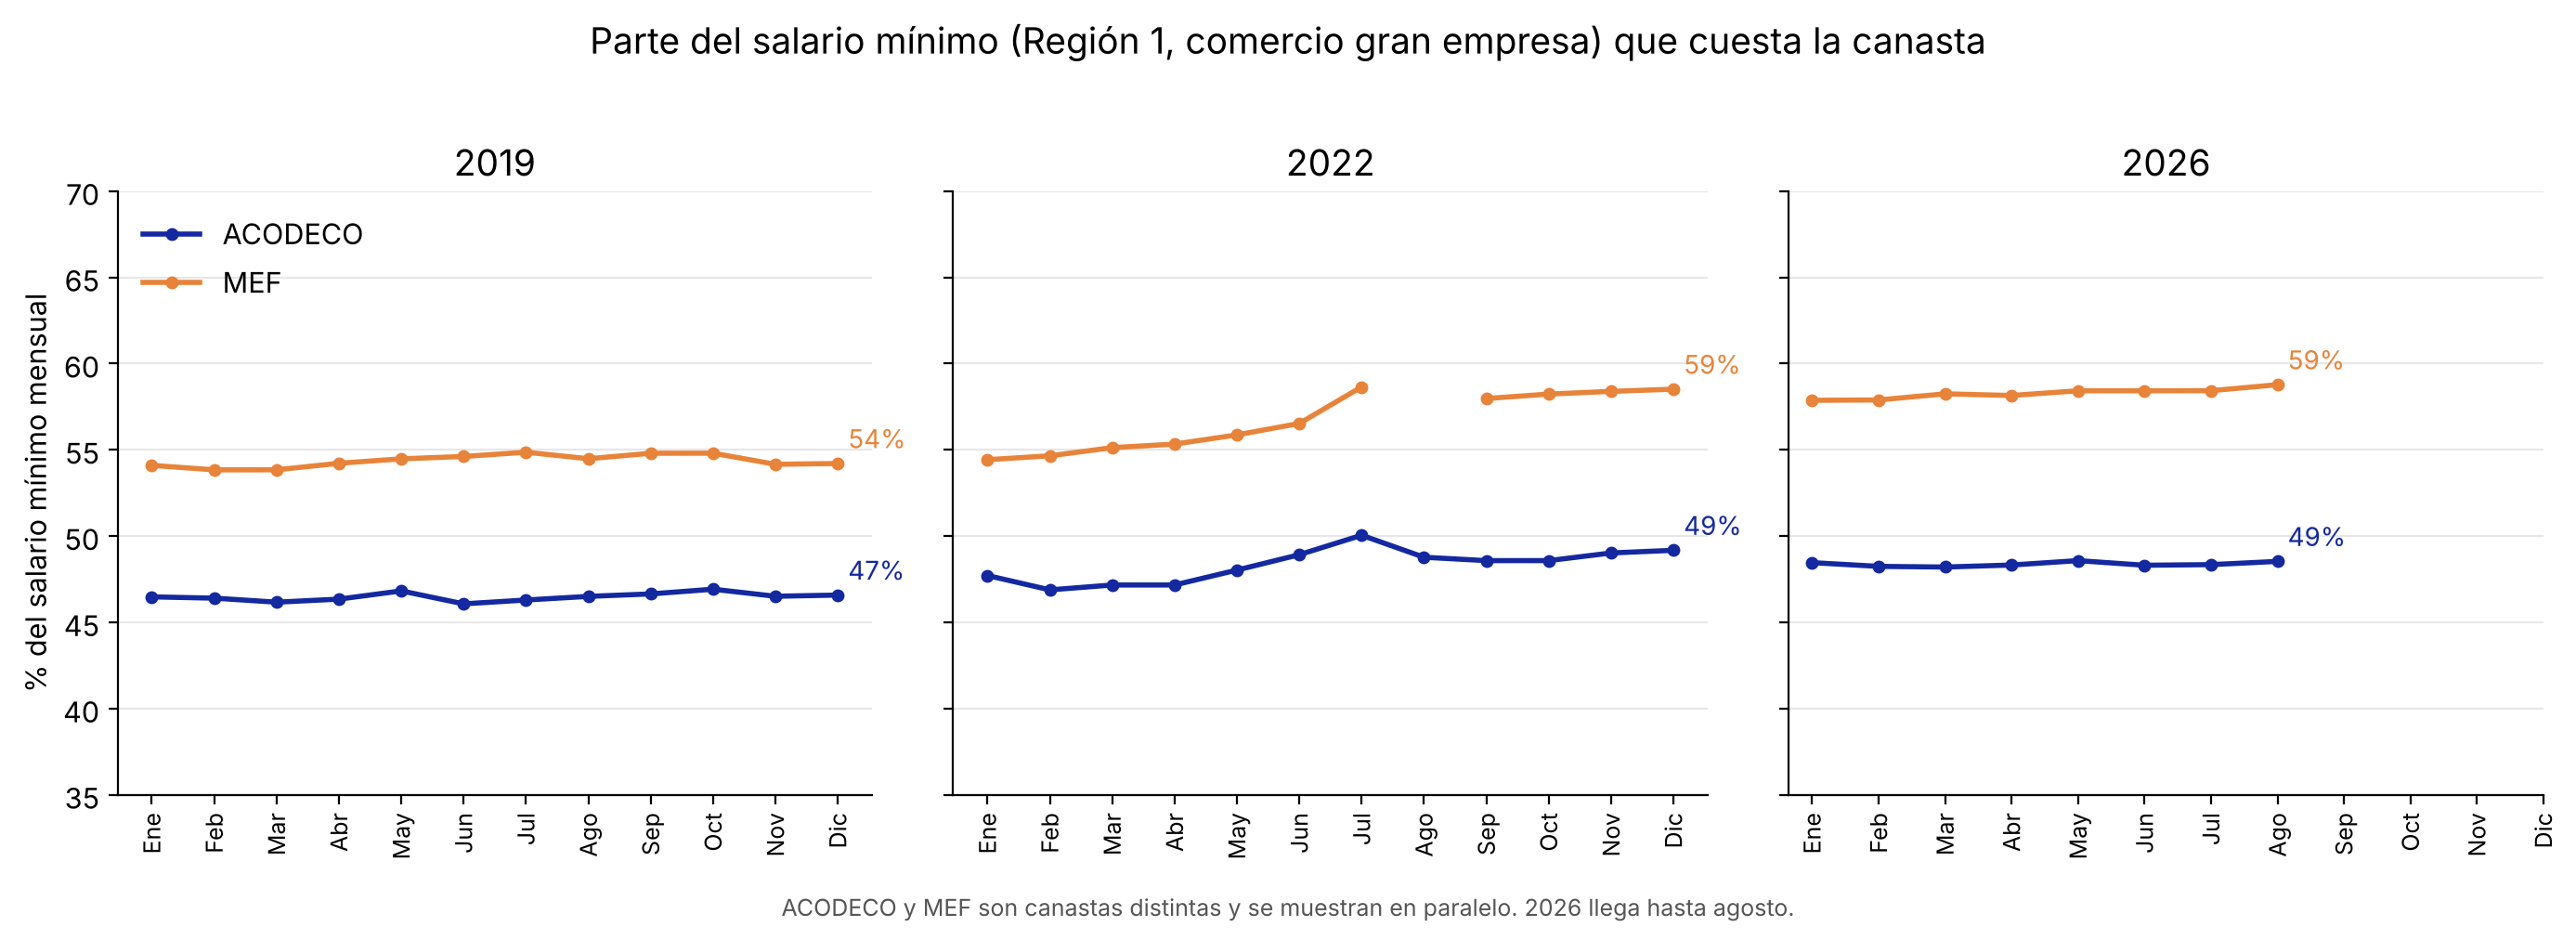

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.6), sharey=True)
for ax, anio in zip(axes, [2019, 2022, 2026]):
    for fuente in ['ACODECO', 'MEF']:
        s = (base[(base['fuente_corta'] == fuente) & (base['anio'] == anio)]
             .set_index('mes')['pct_salario_en_comida']
             .reindex(range(1, 13)))          # los meses sin dato quedan como NaN (hueco)
        ax.plot(range(1, 13), s.values, marker='o', ms=4, lw=2, color=COLOR[fuente], label=fuente)
        ult = s.dropna()
        ax.annotate(f"{ult.iloc[-1]:.0f}%", (ult.index[-1], ult.iloc[-1]),
                    textcoords='offset points', xytext=(4, 6), color=COLOR[fuente], fontsize=10)
    ax.set_title(str(anio))
    ax.set_xticks(range(1, 13))
    ax.set_xticklabels(MESES, rotation=90, fontsize=9)
    ax.grid(axis='y', alpha=.3)
axes[0].set_ylabel('% del salario mínimo mensual')
axes[0].set_ylim(35, 70)
axes[0].legend(frameon=False, loc='upper left')
fig.suptitle('Parte del salario mínimo (Región 1, comercio gran empresa) que cuesta la canasta', y=1.02, fontsize=14)
fig.text(0.5, -0.03, 'ACODECO y MEF son canastas distintas y se muestran en paralelo. 2026 llega hasta agosto.',
         ha='center', fontsize=9, color='#555')
fig.tight_layout()
fig.savefig(figuras / '03_pct_salario_en_comida.png', dpi=150, bbox_inches='tight')
plt.show()

### Figura 2 - Horas de trabajo para pagar la canasta (junio)

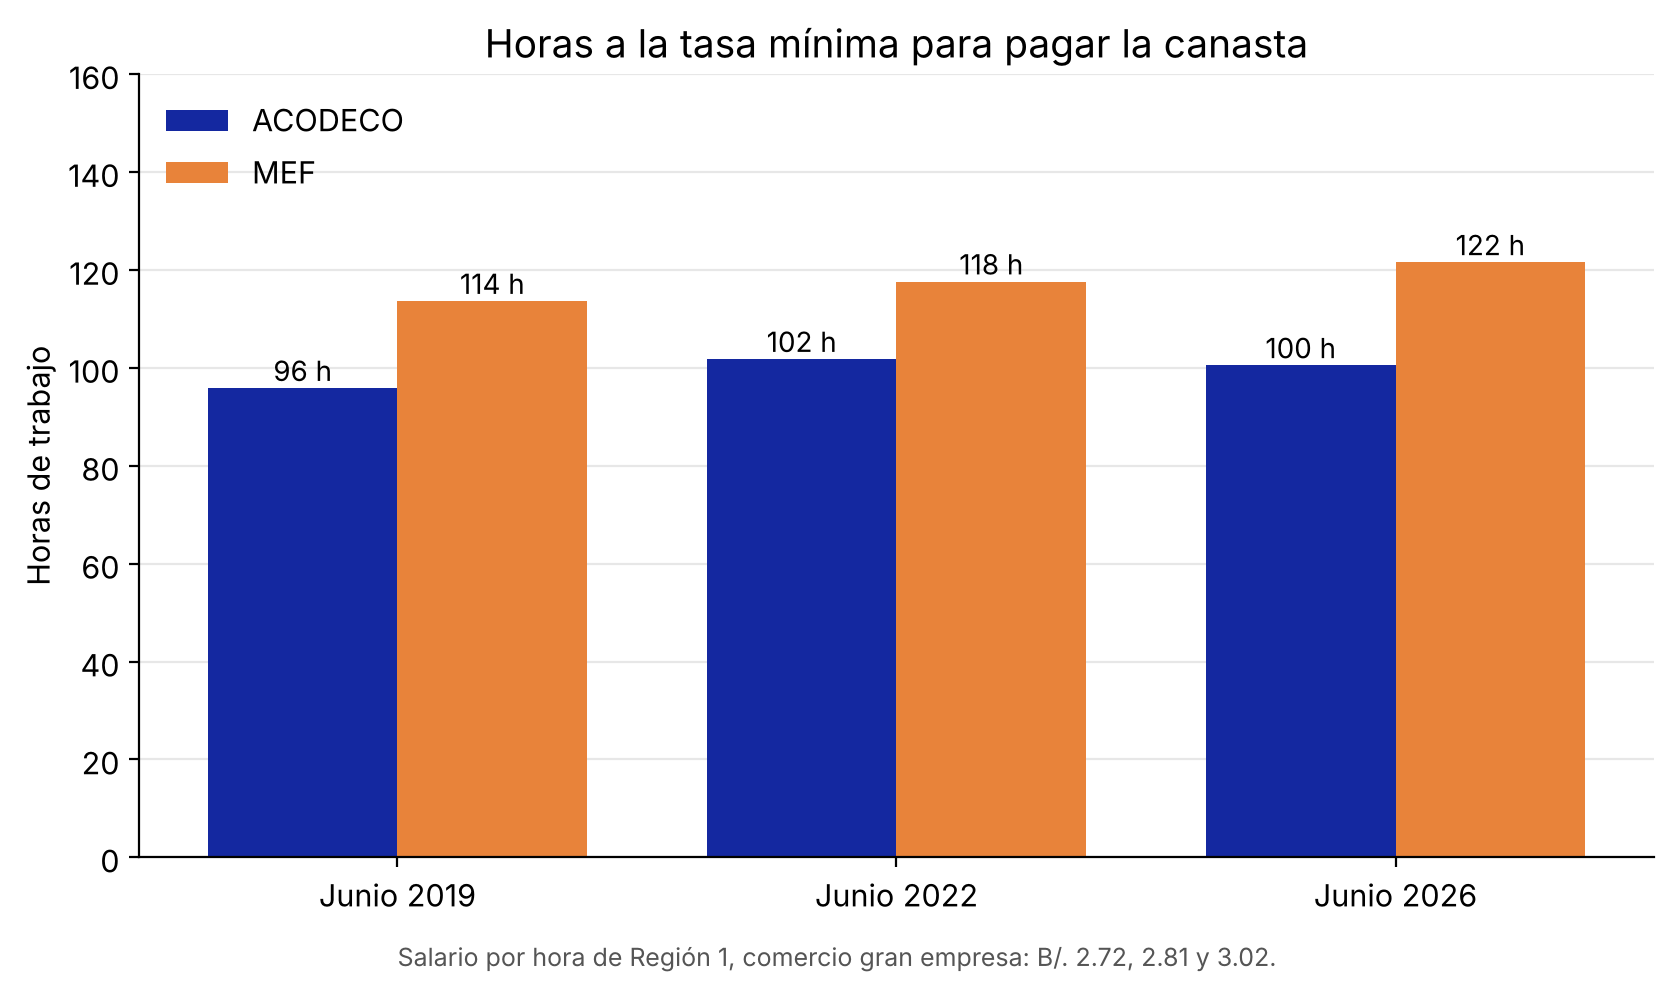

In [8]:
fig, ax = plt.subplots(figsize=(8.5, 4.8))
ancho = 0.38
anios = [2019, 2022, 2026]
for i, fuente in enumerate(['ACODECO', 'MEF']):
    vals = junio.loc[fuente, 'horas_para_pagar'].reindex(anios)
    pos = [k + (i - 0.5) * ancho for k in range(3)]
    barras = ax.bar(pos, vals.values, width=ancho, color=COLOR[fuente], label=fuente)
    for b, v in zip(barras, vals.values):
        ax.text(b.get_x() + b.get_width() / 2, v + 1.5, f"{v:.0f} h", ha='center', fontsize=10)
ax.set_xticks(range(3))
ax.set_xticklabels([f"Junio {a}" for a in anios])
ax.set_ylabel('Horas de trabajo')
ax.set_ylim(0, 160)
ax.grid(axis='y', alpha=.3)
ax.legend(frameon=False, loc='upper left')
ax.set_title('Horas a la tasa mínima para pagar la canasta')
fig.text(0.5, -0.02, 'Salario por hora de Región 1, comercio gran empresa: B/. 2.72, 2.81 y 3.02.',
         ha='center', fontsize=9, color='#555')
fig.tight_layout()
fig.savefig(figuras / '03_horas_para_pagar_canasta.png', dpi=150, bbox_inches='tight')
plt.show()

## 6. ¿La comida subió más que el salario?

Cada mes se compara contra **el mismo mes de 2019** (misma fuente, mismo salario de referencia).

In [9]:
ref = (base[base['anio'] == 2019]
       [['fuente_corta', 'mes', 'costo_total', 'salario_mensual']]
       .rename(columns={'costo_total': 'costo_2019', 'salario_mensual': 'salario_2019'}))

var = base[base['anio'] > 2019].merge(ref, on=['fuente_corta', 'mes'], how='left')
var['var_canasta_%'] = (var['costo_total'] / var['costo_2019'] - 1) * 100
var['var_salario_%'] = (var['salario_mensual'] / var['salario_2019'] - 1) * 100
var['brecha_pp'] = var['var_canasta_%'] - var['var_salario_%']

var_junio = (var[var['mes'] == 6]
             .set_index(['fuente_corta', 'anio'])
             [['costo_2019', 'costo_total', 'var_canasta_%', 'salario_2019', 'salario_mensual',
               'var_salario_%', 'brecha_pp']])
var_junio.round(1)

costo_2019  costo_total  var_canasta_%  salario_2019  \
fuente_corta anio                                                         
ACODECO      2022       260.6        285.9            9.7         565.8   
             2026       260.6        303.4           16.4         565.8   
MEF          2022       309.0        330.4            6.9         565.8   
             2026       309.0        367.0           18.8         565.8   

                   salario_mensual  var_salario_%  brecha_pp  
fuente_corta anio                                             
ACODECO      2022            584.5            3.3        6.4  
             2026            628.2           11.0        5.4  
MEF          2022            584.5            3.3        3.6  
             2026            628.2           11.0        7.7

### Figura 3 - Aumento de la canasta vs aumento del salario (junio vs junio de 2019)

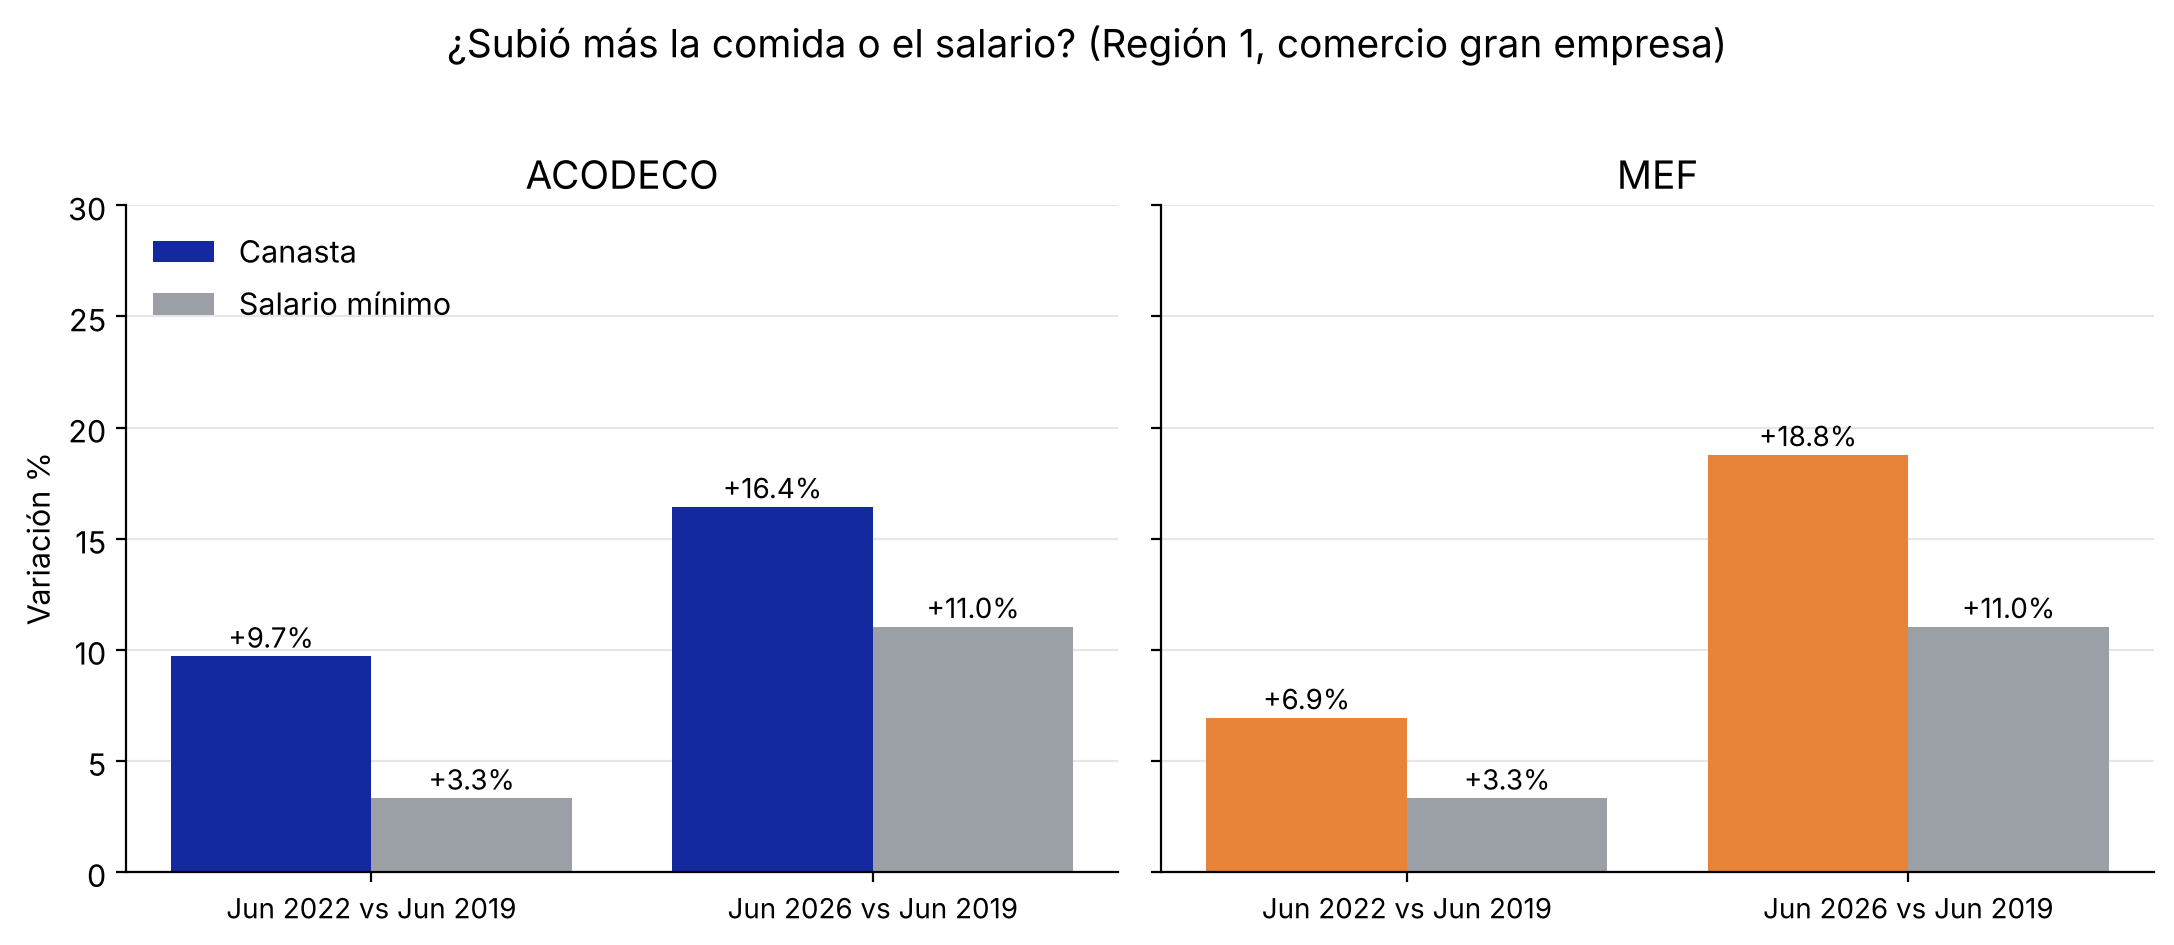

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.6), sharey=True)
for ax, fuente in zip(axes, ['ACODECO', 'MEF']):
    d = var_junio.loc[fuente]
    x = range(len(d))
    b1 = ax.bar([i - 0.2 for i in x], d['var_canasta_%'], width=0.4, color=COLOR[fuente], label='Canasta')
    b2 = ax.bar([i + 0.2 for i in x], d['var_salario_%'], width=0.4, color='#9aa0a6', label='Salario mínimo')
    for b in list(b1) + list(b2):
        ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 0.4, f"{b.get_height():+.1f}%",
                ha='center', fontsize=10)
    ax.set_xticks(list(x))
    ax.set_xticklabels([f"Jun {a} vs Jun 2019" for a in d.index], fontsize=10)
    ax.set_title(fuente)
    ax.grid(axis='y', alpha=.3)
axes[0].set_ylabel('Variación %')
axes[0].legend(frameon=False, loc='upper left')
axes[0].set_ylim(0, 30)
fig.suptitle('¿Subió más la comida o el salario? (Región 1, comercio gran empresa)', y=1.02, fontsize=14)
fig.tight_layout()
fig.savefig(figuras / '03_variacion_canasta_vs_salario.png', dpi=150, bbox_inches='tight')
plt.show()

## 7. Sensibilidad: otras categorías de la Región 1 (junio, canasta ACODECO)

Solo como contraste; **no cambia** la categoría ni las figuras principales. La Región 2 no se cruza con la canasta.
En trabajo doméstico no hay tasa por hora, así que ahí solo se calcula el porcentaje.

In [11]:
aco_junio = costo[(costo['fuente'] == 'acodeco_historico') & (costo['mes'] == 6)][['anio', 'costo_total']]

sens = (salario[salario['region'] == 1]
        .merge(aco_junio, left_on='anio_analisis', right_on='anio')
        .assign(pct_salario_en_comida=lambda d: d['costo_total'] / d['salario_mensual'] * 100,
                horas_para_pagar=lambda d: d['costo_total'] / d['salario_hora']))

sens_tabla = (sens.pivot_table(index='categoria', columns='anio_analisis',
                               values=['pct_salario_en_comida', 'horas_para_pagar'])
              .round(1))
sens_tabla

horas_para_pagar               pct_salario_en_comida  \
anio_analisis                    2019   2022   2026                  2019   
categoria                                                                   
domestico                         NaN    NaN    NaN                  94.8   
gran_empresa                     95.8  101.8  100.5                  46.1   
pequena                         118.5  126.0  128.0                  57.0   
supermercados_5_plus              NaN   99.3   98.2                   NaN   

                                  
anio_analisis         2022  2026  
categoria                         
domestico             90.8  86.7  
gran_empresa          48.9  48.3  
pequena               60.6  61.6  
supermercados_5_plus  47.7  47.2

## 8. Guardar la tabla de resultados

In [12]:
final = (base[['fuente', 'fecha', 'anio', 'mes', 'costo_total', 'salario_hora', 'salario_mensual',
               'pct_salario_en_comida', 'horas_para_pagar']]
         .round({'pct_salario_en_comida': 2, 'horas_para_pagar': 2})
         .sort_values(['fuente', 'fecha']))
final.to_csv(tablas / '03_poder_adquisitivo.csv', index=False)
print(final.shape, '->', tablas / '03_poder_adquisitivo.csv')
print([p.name for p in sorted(figuras.glob('03_*.png'))])

(63, 9) -> ../outputs/tablas/03_poder_adquisitivo.csv
['03_horas_para_pagar_canasta.png', '03_pct_salario_en_comida.png', '03_variacion_canasta_vs_salario.png']


## 9. Conclusiones

In [13]:
a = junio.loc['ACODECO']
m = junio.loc['MEF']
va = var_junio.loc['ACODECO']
vm = var_junio.loc['MEF']

print("Con el salario mínimo de Región 1 (comercio, gran empresa):")
print(f"- Canasta ACODECO: pasa de {a.loc[2019,'pct_salario_en_comida']:.0f}% del salario en junio 2019 "
      f"a {a.loc[2022,'pct_salario_en_comida']:.0f}% en 2022 y {a.loc[2026,'pct_salario_en_comida']:.0f}% en 2026.")
print(f"  Horas para pagarla: {a.loc[2019,'horas_para_pagar']:.0f} h -> {a.loc[2022,'horas_para_pagar']:.0f} h "
      f"-> {a.loc[2026,'horas_para_pagar']:.0f} h.")
print(f"- Canasta MEF (otra metodología, aparte): {m.loc[2019,'pct_salario_en_comida']:.0f}% -> "
      f"{m.loc[2022,'pct_salario_en_comida']:.0f}% -> {m.loc[2026,'pct_salario_en_comida']:.0f}% del salario; "
      f"{m.loc[2019,'horas_para_pagar']:.0f} h -> {m.loc[2022,'horas_para_pagar']:.0f} h -> {m.loc[2026,'horas_para_pagar']:.0f} h.")
print(f"- Jun 2026 vs Jun 2019: la canasta ACODECO subió {va.loc[2026,'var_canasta_%']:.1f}% y el salario "
      f"{va.loc[2026,'var_salario_%']:.1f}% (brecha {va.loc[2026,'brecha_pp']:.1f} pp). "
      f"En MEF: canasta {vm.loc[2026,'var_canasta_%']:.1f}% vs salario {vm.loc[2026,'var_salario_%']:.1f}%.")

Con el salario mínimo de Región 1 (comercio, gran empresa):
- Canasta ACODECO: pasa de 46% del salario en junio 2019 a 49% en 2022 y 48% en 2026.
  Horas para pagarla: 96 h -> 102 h -> 100 h.
- Canasta MEF (otra metodología, aparte): 55% -> 57% -> 58% del salario; 114 h -> 118 h -> 122 h.
- Jun 2026 vs Jun 2019: la canasta ACODECO subió 16.4% y el salario 11.0% (brecha 5.4 pp). En MEF: canasta 18.8% vs salario 11.0%.


**Límites a tener presentes**

- Es una persona sola frente a una canasta de 59 productos (ACODECO) o un costo calórico familiar (MEF): las dos son referencias, no el gasto real de un hogar. Por eso se muestran por separado.
- El salario es el de la categoría declarada arriba; otras categorías cambian el porcentaje (ver sección 7).
- El salario se toma constante dentro del año de análisis; 2026 llega solo hasta agosto en el costo.
- Con tres cortes en el tiempo (2019, 2022, 2026) se ve la tendencia, no la evolución mes a mes de los años intermedios.